# Praktikum Data Mining: Clustering Advanced
Nama: Fahmi Alfayadh \
NRP: 5054251015\
Kelas: Data Mining (N)

## inisialisasi data

In [190]:
import matplotlib.pyplot as plt
import polars as pl
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

import polars.selectors as ps

In [169]:
df = pl.read_csv('dataset.csv')
df

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
str,str,str,str,str,str,str,i64
"""Adelie""","""Torgersen""","""39.1""","""18.7""","""181""","""3750""","""male""",2007
"""Adelie""","""Torgersen""","""39.5""","""17.4""","""186""","""3800""","""female""",2007
"""Adelie""","""Torgersen""","""40.3""","""18""","""195""","""3250""","""female""",2007
"""Adelie""","""Torgersen""","""NA""","""NA""","""NA""","""NA""","""NA""",2007
"""Adelie""","""Torgersen""","""36.7""","""19.3""","""193""","""3450""","""female""",2007
…,…,…,…,…,…,…,…
"""Chinstrap""","""Dream""","""55.8""","""19.8""","""207""","""4000""","""male""",2009
"""Chinstrap""","""Dream""","""43.5""","""18.1""","""202""","""3400""","""female""",2009
"""Chinstrap""","""Dream""","""49.6""","""18.2""","""193""","""3775""","""male""",2009


In [170]:
print(f"null sum: {df.null_count().sum()} ")
print(f"duplicated sum: {df.is_duplicated().sum()}")

null sum: shape: (1, 8)
┌─────────┬────────┬────────────────┬───────────────┬───────────────────┬─────────────┬─────┬──────┐
│ species ┆ island ┆ bill_length_mm ┆ bill_depth_mm ┆ flipper_length_mm ┆ body_mass_g ┆ sex ┆ year │
│ ---     ┆ ---    ┆ ---            ┆ ---           ┆ ---               ┆ ---         ┆ --- ┆ ---  │
│ u32     ┆ u32    ┆ u32            ┆ u32           ┆ u32               ┆ u32         ┆ u32 ┆ u32  │
╞═════════╪════════╪════════════════╪═══════════════╪═══════════════════╪═════════════╪═════╪══════╡
│ 0       ┆ 0      ┆ 0              ┆ 0             ┆ 0                 ┆ 0           ┆ 0   ┆ 0    │
└─────────┴────────┴────────────────┴───────────────┴───────────────────┴─────────────┴─────┴──────┘ 
duplicated sum: 0


dataset saat ini bersih dari null dan duplikat, tapi banyak numeric yg dibaca string dan belom "NA" belum diubah ke null, jadi perlu dibersihkan lagi

In [171]:
df = df.with_columns(
    pl.col('bill_depth_mm').cast(pl.Float32, strict=False),
    pl.col('bill_length_mm').cast(pl.Float32, strict=False),
    pl.col('flipper_length_mm').cast(pl.Float32, strict=False),
    pl.col('body_mass_g').cast(pl.Float32, strict=False),
    pl.col("sex").str.replace("NA", None)
)

In [172]:
df

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
str,str,f32,f32,f32,f32,str,i64
"""Adelie""","""Torgersen""",39.099998,18.700001,181.0,3750.0,"""male""",2007
"""Adelie""","""Torgersen""",39.5,17.4,186.0,3800.0,"""female""",2007
"""Adelie""","""Torgersen""",40.299999,18.0,195.0,3250.0,"""female""",2007
"""Adelie""","""Torgersen""",null,null,null,null,"""NA""",2007
"""Adelie""","""Torgersen""",36.700001,19.299999,193.0,3450.0,"""female""",2007
…,…,…,…,…,…,…,…
"""Chinstrap""","""Dream""",55.799999,19.799999,207.0,4000.0,"""male""",2009
"""Chinstrap""","""Dream""",43.5,18.1,202.0,3400.0,"""female""",2009
"""Chinstrap""","""Dream""",49.599998,18.200001,193.0,3775.0,"""male""",2009


In [173]:
df.null_count().sum()
df.drop_nulls()

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
str,str,f32,f32,f32,f32,str,i64
"""Adelie""","""Torgersen""",39.099998,18.700001,181.0,3750.0,"""male""",2007
"""Adelie""","""Torgersen""",39.5,17.4,186.0,3800.0,"""female""",2007
"""Adelie""","""Torgersen""",40.299999,18.0,195.0,3250.0,"""female""",2007
"""Adelie""","""Torgersen""",36.700001,19.299999,193.0,3450.0,"""female""",2007
"""Adelie""","""Torgersen""",39.299999,20.6,190.0,3650.0,"""male""",2007
…,…,…,…,…,…,…,…
"""Chinstrap""","""Dream""",55.799999,19.799999,207.0,4000.0,"""male""",2009
"""Chinstrap""","""Dream""",43.5,18.1,202.0,3400.0,"""female""",2009
"""Chinstrap""","""Dream""",49.599998,18.200001,193.0,3775.0,"""male""",2009


In [174]:
print('==== Before dropping nulls and duplicates == ')
print(f"null sum: {df.null_count().sum()} ")
print(f"duplicated sum: {df.is_duplicated().sum()}")
print(f"shape: {df.shape} ")

df = df.drop_nulls()
df = df.unique()

print('======= after dropping nulls and duplicates ======= ')
print(f"null sum: {df.null_count().sum()} ")
print(f"duplicated sum: {df.is_duplicated().sum()}")
print(f"shape: {df.shape} ")


==== Before dropping nulls and duplicates == 
null sum: shape: (1, 8)
┌─────────┬────────┬────────────────┬───────────────┬───────────────────┬─────────────┬─────┬──────┐
│ species ┆ island ┆ bill_length_mm ┆ bill_depth_mm ┆ flipper_length_mm ┆ body_mass_g ┆ sex ┆ year │
│ ---     ┆ ---    ┆ ---            ┆ ---           ┆ ---               ┆ ---         ┆ --- ┆ ---  │
│ u32     ┆ u32    ┆ u32            ┆ u32           ┆ u32               ┆ u32         ┆ u32 ┆ u32  │
╞═════════╪════════╪════════════════╪═══════════════╪═══════════════════╪═════════════╪═════╪══════╡
│ 0       ┆ 0      ┆ 2              ┆ 2             ┆ 2                 ┆ 2           ┆ 0   ┆ 0    │
└─────────┴────────┴────────────────┴───────────────┴───────────────────┴─────────────┴─────┴──────┘ 
duplicated sum: 0
shape: (344, 8) 
======= after dropping nulls and duplicates ======= 
null sum: shape: (1, 8)
┌─────────┬────────┬────────────────┬───────────────┬───────────────────┬─────────────┬─────┬──────┐
│ species

## Visualisai Data

### Distribusi histogram numeric cols

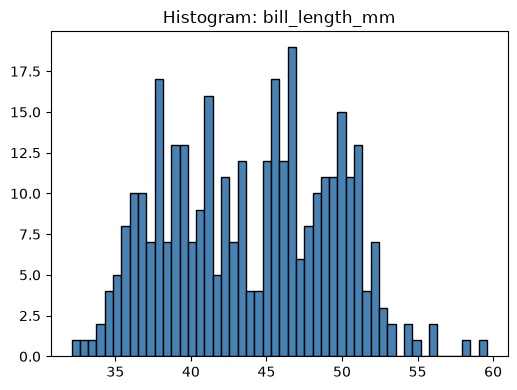

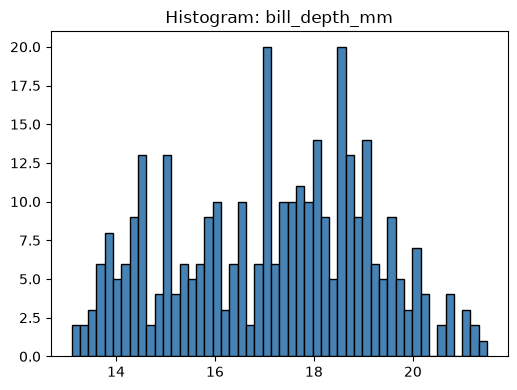

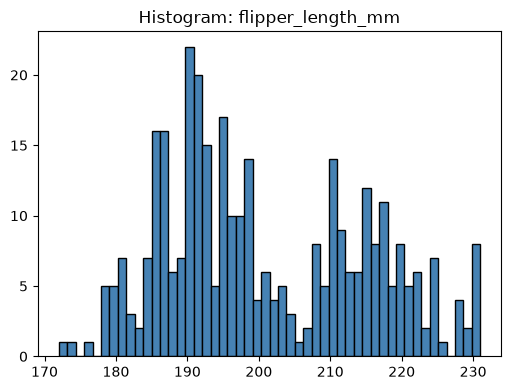

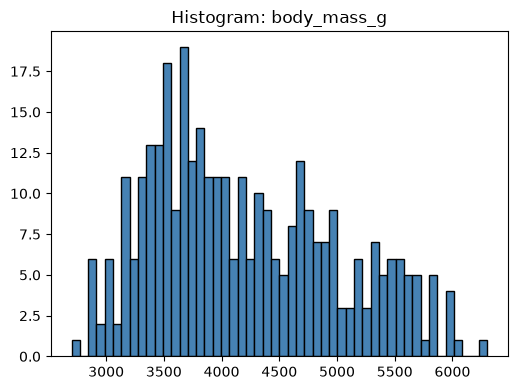

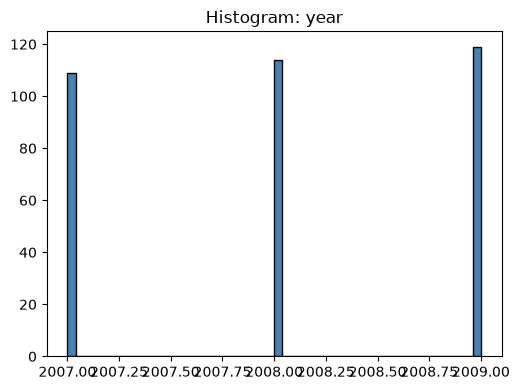

In [175]:
numeric_cols = df.select(ps.numeric()).columns

for kolom in numeric_cols:
    arr = df[kolom].to_numpy()

    plt.figure(figsize=(10, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(arr, bins=50, edgecolor="black", color="steelblue")
    plt.title(f"Histogram: {kolom}")

    plt.tight_layout()
    plt.show()

### Scatter plot bill, flipper, dan body mass

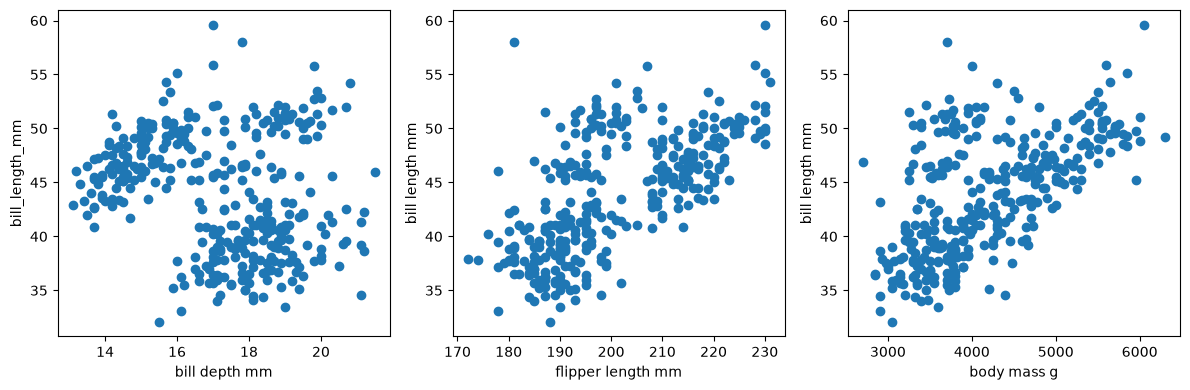

In [176]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (12,4))

ax1.scatter(df['bill_depth_mm'].to_numpy(), df['bill_length_mm'].to_numpy())
ax1.set_xlabel("bill depth mm") 
ax1.set_ylabel("bill_length_mm")


ax2.scatter(df["flipper_length_mm"].to_numpy(), df["bill_length_mm"].to_numpy())
ax2.set_xlabel("flipper length mm")
ax2.set_ylabel("bill length mm")

ax3.scatter(df["body_mass_g"].to_numpy(), df["bill_length_mm"].to_numpy())
ax3.set_xlabel("body mass g")
ax3.set_ylabel("bill length mm")

plt.tight_layout()
plt.show()


### Standarisasi Data

In [177]:
X = df.select(ps.numeric())
y = df.select(pl.col("species"))

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")


X shape: (342, 5)
y shape: (342, 1)


In [178]:
import pandas as pd

In [179]:
scaler = StandardScaler()

X_transformed = scaler.fit_transform(X)
X_transformed = pd.DataFrame(X_transformed, columns=X.columns)

In [180]:
X_transformed

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,1.261662,0.684024,0.006039,0.310004,1.189697
1,0.619648,-1.699459,1.074328,0.653419,1.189697
2,0.894797,-0.482361,1.501644,2.245614,1.189697
3,-0.792783,0.278326,-1.062250,-0.876337,-0.035834
4,-1.416453,0.075475,-0.991031,-1.126093,-0.035834
...,...,...,...,...,...
337,-0.517634,0.988299,-0.919812,-0.127069,-0.035834
338,0.216096,-1.344472,0.433355,1.059273,-1.261365
339,1.518467,0.836161,-0.278838,-0.938776,1.189697
340,-0.334201,0.988299,-0.421277,-0.251947,-0.035834


<Axes: >

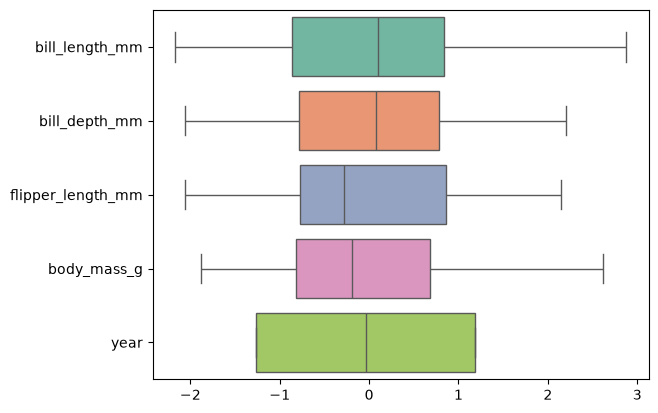

In [181]:
sns.boxplot(data=X_transformed, orient="h", palette="Set2")

## Clustering

In [182]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

### definisi model

In [183]:
algomorative = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",
    )

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="euclidean",
    )

spectral = SpectralClustering(
    n_clusters=3,
    affinity="nearest_neighbors",
    assign_labels="kmeans",
    )

gmm = GaussianMixture(
    n_components=3,
    covariance_type="full", 
)



### Training model

In [184]:
algomorative.fit(X_transformed)
dbscan.fit(X_transformed)
spectral.fit(X_transformed)
gmm.fit(X_transformed)

/cache/ml/.venv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,"n_components n_components: int, default=1The number of mixture components.",3
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None


### Visualisasi hasil clustering

Text(0.5, 1.0, 'Gaussian Mixture Model')

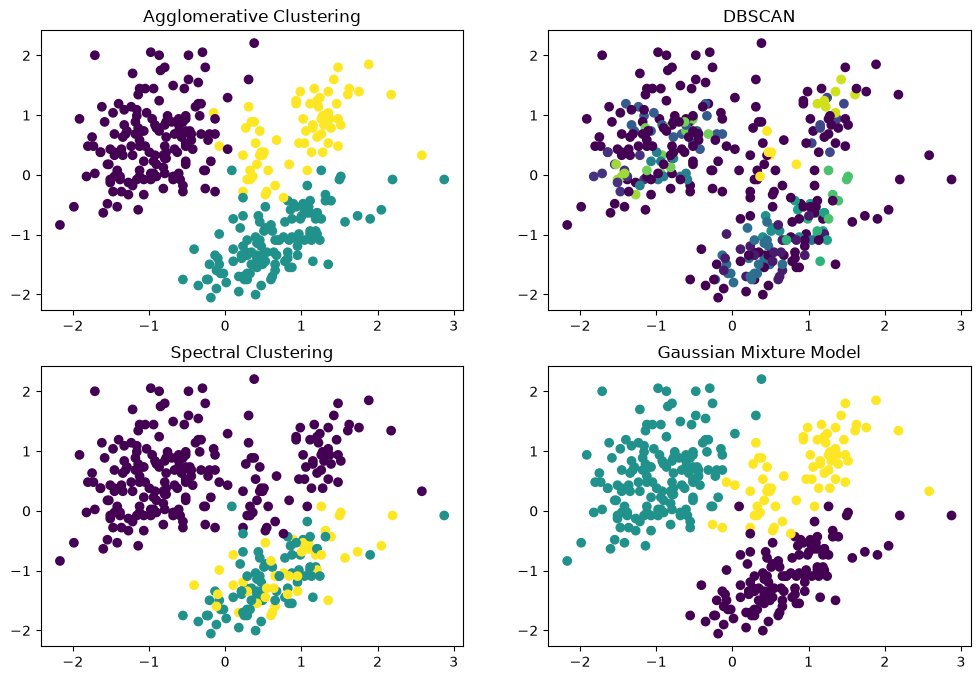

In [185]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))

ax1.scatter(X_transformed.iloc[:, 0], X_transformed.iloc[:, 1], c=algomorative.labels_, cmap='viridis')
ax1.set_title("Agglomerative Clustering")

ax2.scatter(X_transformed.iloc[:, 0], X_transformed.iloc[:, 1], c=dbscan.labels_, cmap='viridis')
ax2.set_title("DBSCAN")

ax3.scatter(X_transformed.iloc[:, 0], X_transformed.iloc[:, 1], c=spectral.labels_, cmap='viridis')
ax3.set_title("Spectral Clustering")

ax4.scatter(X_transformed.iloc[:, 0], X_transformed.iloc[:, 1], c=gmm.predict(X_transformed), cmap='viridis')
ax4.set_title("Gaussian Mixture Model")

### training lanjutan db scan

DBSCAN with eps=0.1:
DBSCAN with eps=0.5:
DBSCAN with eps=1.0:
DBSCAN with eps=2.0:
DBSCAN with eps=5.0:


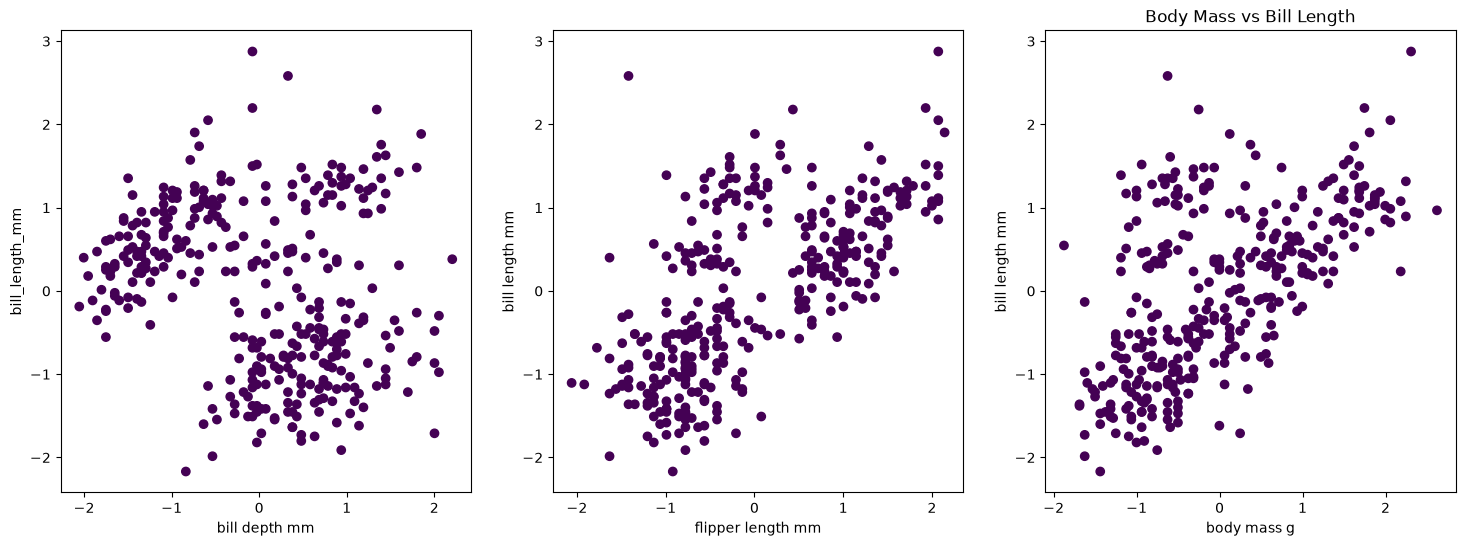

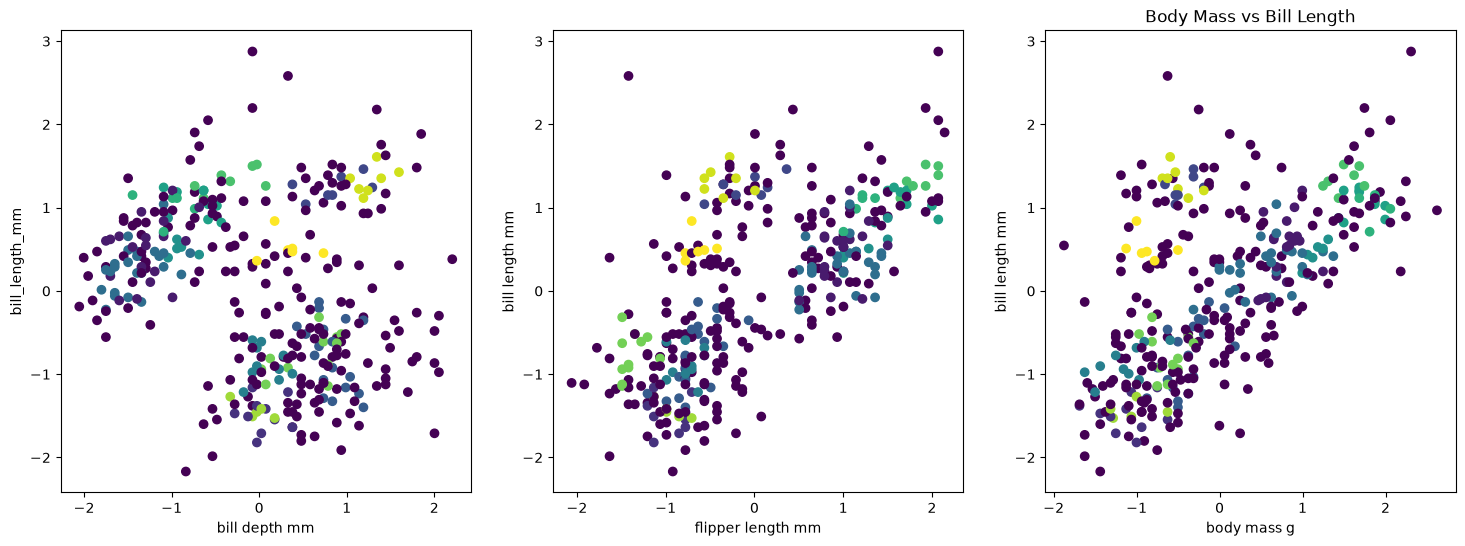

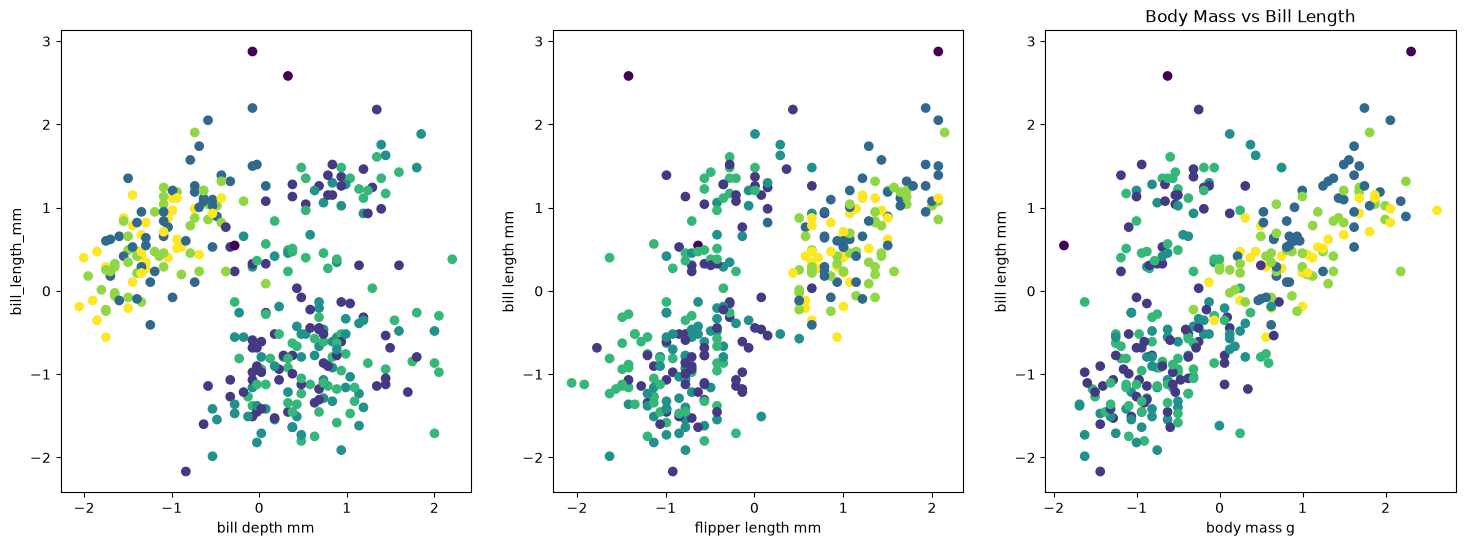

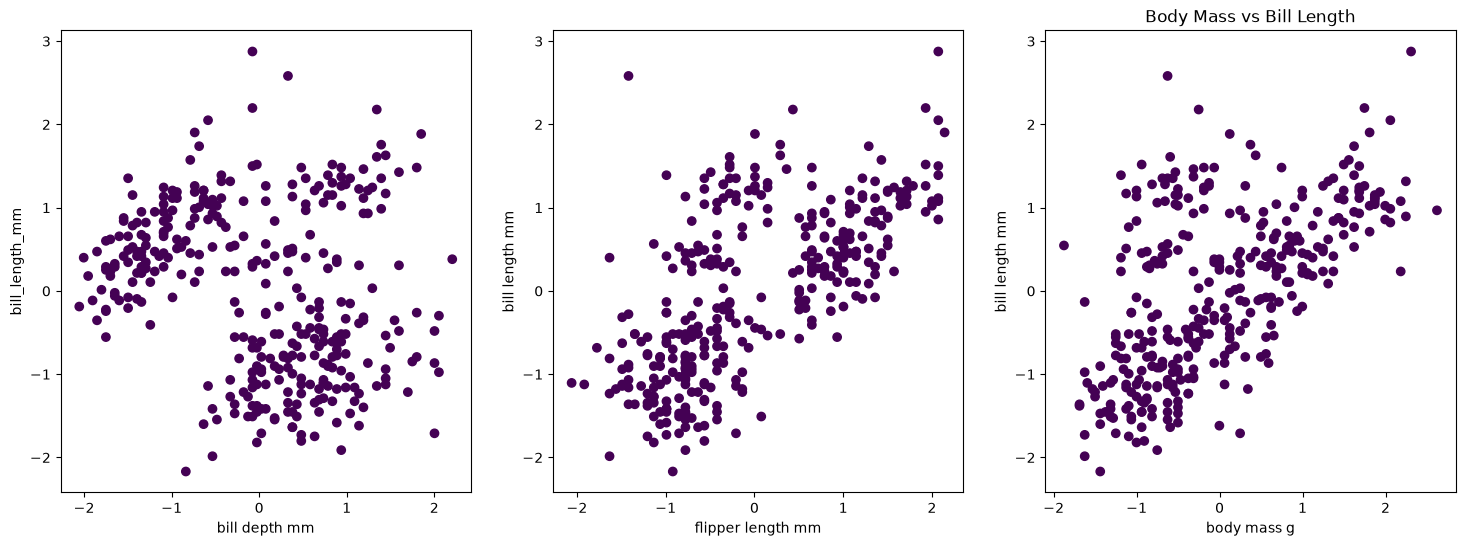

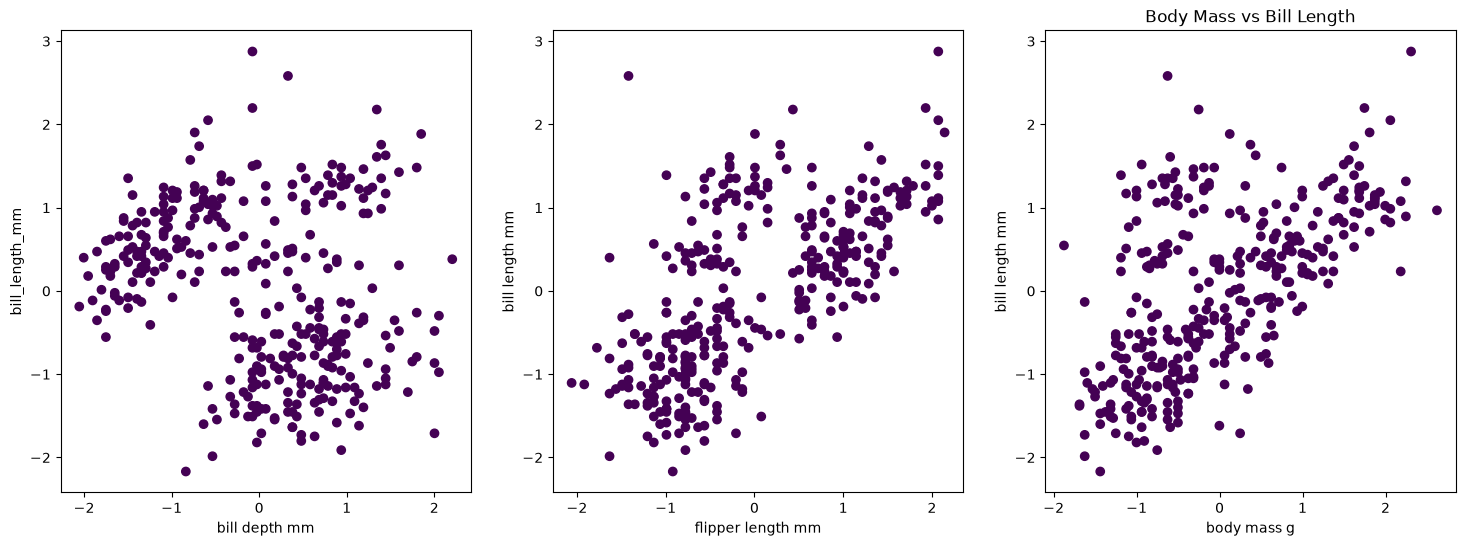

In [191]:
alpha = [0.1, 0.5, 1.0, 2.0, 5.0]

for a in alpha:
    dbscan = DBSCAN(
        eps=a,
        min_samples=5,
        metric="euclidean",
    )
    dbscan.fit(X_transformed)

    
    print(f"DBSCAN with eps={a}:")

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
    ax1.scatter(X_transformed['bill_depth_mm'], X_transformed['bill_length_mm'], c=dbscan.labels_, cmap='viridis')
    ax1.set_xlabel("bill depth mm") 
    ax1.set_ylabel("bill_length_mm")

    ax2.scatter(X_transformed["flipper_length_mm"], X_transformed["bill_length_mm"], c=dbscan.labels_, cmap='viridis')
    ax2.set_xlabel("flipper length mm")
    ax2.set_ylabel("bill length mm")

    ax3.scatter(X_transformed["body_mass_g"], X_transformed["bill_length_mm"], c=dbscan.labels_, cmap='viridis')
    ax3.set_xlabel("body mass g")
    ax3.set_ylabel("bill length mm")
    ax3.set_title("Body Mass vs Bill Length")



In [192]:
dbscan_best = DBSCAN(
    eps=1,
    min_samples=5,
    metric="euclidean",
)

dbscan_best.fit(X_transformed)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",1
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](323, 5)","[[ 1.26, 0.68, 0.01, 0.31, 1.19], [ 0.62,-1.7 , 1.07, 0.65, 1.19], [ 0.89,-0.48, 1.5 , 2.25, 1.19], ..., [ 1.52, 0.84,-0.28,-0.94, 1.19], [-0.33, 0.99,-0.42,-0.25,-0.04], [-1.05, 0.48,-1.13,-0.31,-1.26]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](323,)","[ 0, 1, 2,...,339,340,341]"


### Evaluasi model

In [188]:
from sklearn.metrics import normalized_mutual_info_score

silhouette_scores = {
    "Agglomerative Clustering": silhouette_score(X_transformed, algomorative.labels_),
    "DBSCAN": silhouette_score(X_transformed, dbscan_best.labels_),
    "Spectral Clustering": silhouette_score(X_transformed, spectral.labels_),
    "Gaussian Mixture Model": silhouette_score(X_transformed, gmm.predict(X_transformed)),
}

calinski_harabasz_scores = {
    "Agglomerative Clustering": calinski_harabasz_score(X_transformed, algomorative.labels_),
    "DBSCAN": calinski_harabasz_score(X_transformed, dbscan_best.labels_),
    "Spectral Clustering": calinski_harabasz_score(X_transformed, spectral.labels_),
    "Gaussian Mixture Model": calinski_harabasz_score(X_transformed, gmm.predict(X_transformed)),
}

random_index_scores = {
    "Agglomerative Clustering": davies_bouldin_score(X_transformed, algomorative.labels_),
    "DBSCAN": davies_bouldin_score(X_transformed, dbscan_best.labels_),
    "Spectral Clustering": davies_bouldin_score(X_transformed, spectral.labels_),
    "Gaussian Mixture Model": davies_bouldin_score(X_transformed, gmm.predict(X_transformed)),
}

nmi_scores = {
    "Agglomerative Clustering": normalized_mutual_info_score(y.to_numpy().flatten(), algomorative.labels_),
    "DBSCAN": normalized_mutual_info_score(y.to_numpy().flatten(), dbscan_best.labels_),
    "Spectral Clustering": normalized_mutual_info_score(y.to_numpy().flatten(), spectral.labels_),
    "Gaussian Mixture Model": normalized_mutual_info_score(y.to_numpy().flatten(), gmm.predict(X_transformed)),
}

Text(0.5, 1.0, 'Normalized Mutual Information Score')

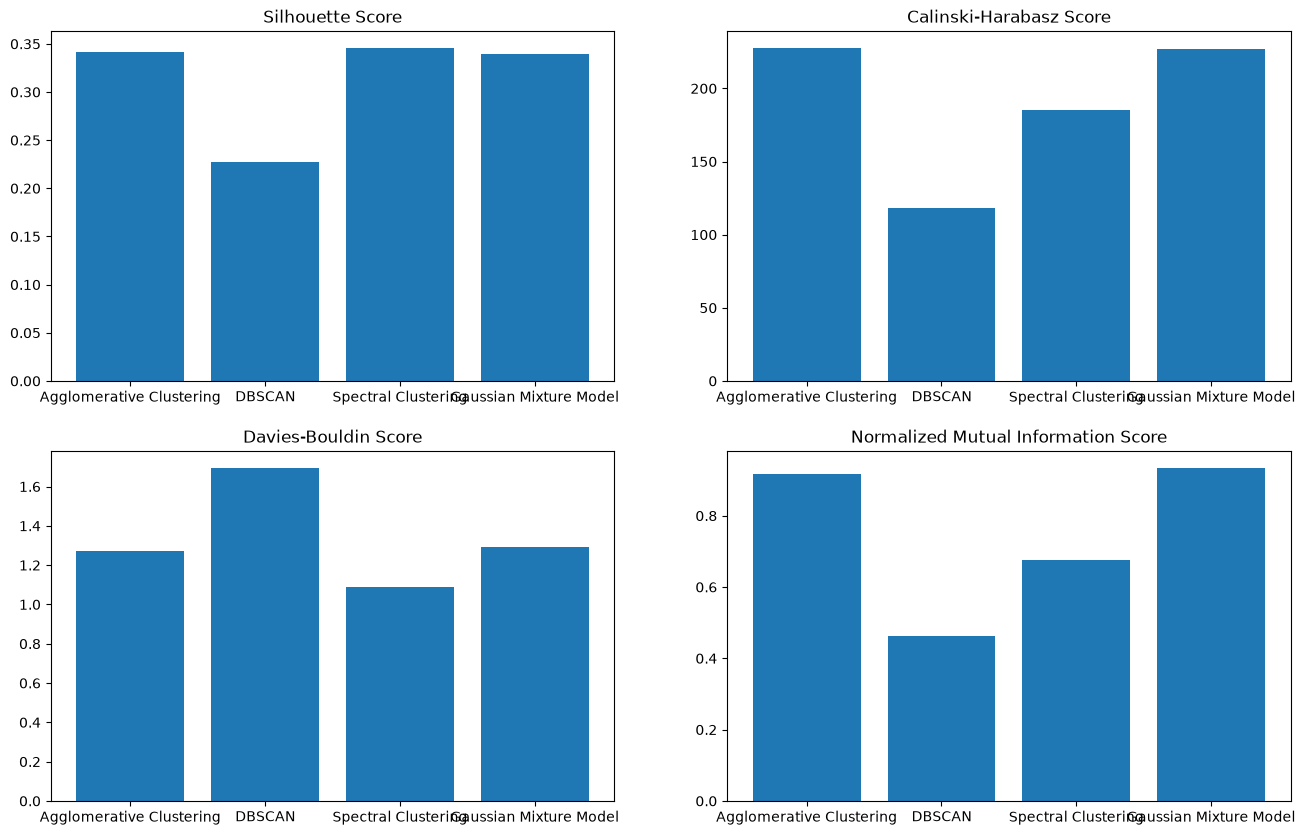

In [189]:
### tampilkan hasil score

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].bar(silhouette_scores.keys(), silhouette_scores.values())
axes[0, 0].set_title("Silhouette Score")
axes[0, 1].bar(calinski_harabasz_scores.keys(), calinski_harabasz_scores.values())
axes[0, 1].set_title("Calinski-Harabasz Score")
axes[1, 0].bar(random_index_scores.keys(), random_index_scores.values())
axes[1, 0].set_title("Davies-Bouldin Score")
axes[1, 1].bar(nmi_scores.keys(), nmi_scores.values())  
axes[1, 1].set_title("Normalized Mutual Information Score")

### Who wins?
Menurut saya, model terbaik pada dataset ini adalah algomorative clustering. walaupun 2 model lainnya (Selain dbscan) memiliki silhouette score yang hampir identik, `NMI score` dan `Calinski-Harabasz score` dari algomorative clustering lebih tinggi dibandingkan model lainnya. 

Sedangkan DBSCan memiliki silhouette score yang rendah, dan NMI score yang rendah juga. Hal ini dikarenakan DBSCAN tidak dapat menemukan cluster yang baik pada dataset ini, bisa dilihhat juga dari hasil visualisasi clusteringnya, tidak ada cluster yang terbentuk dengan baik dari alpha 0.5 sampe 5